# US

APIキーを読み込みました。データを取得中...
取得完了！グラフを描画します。


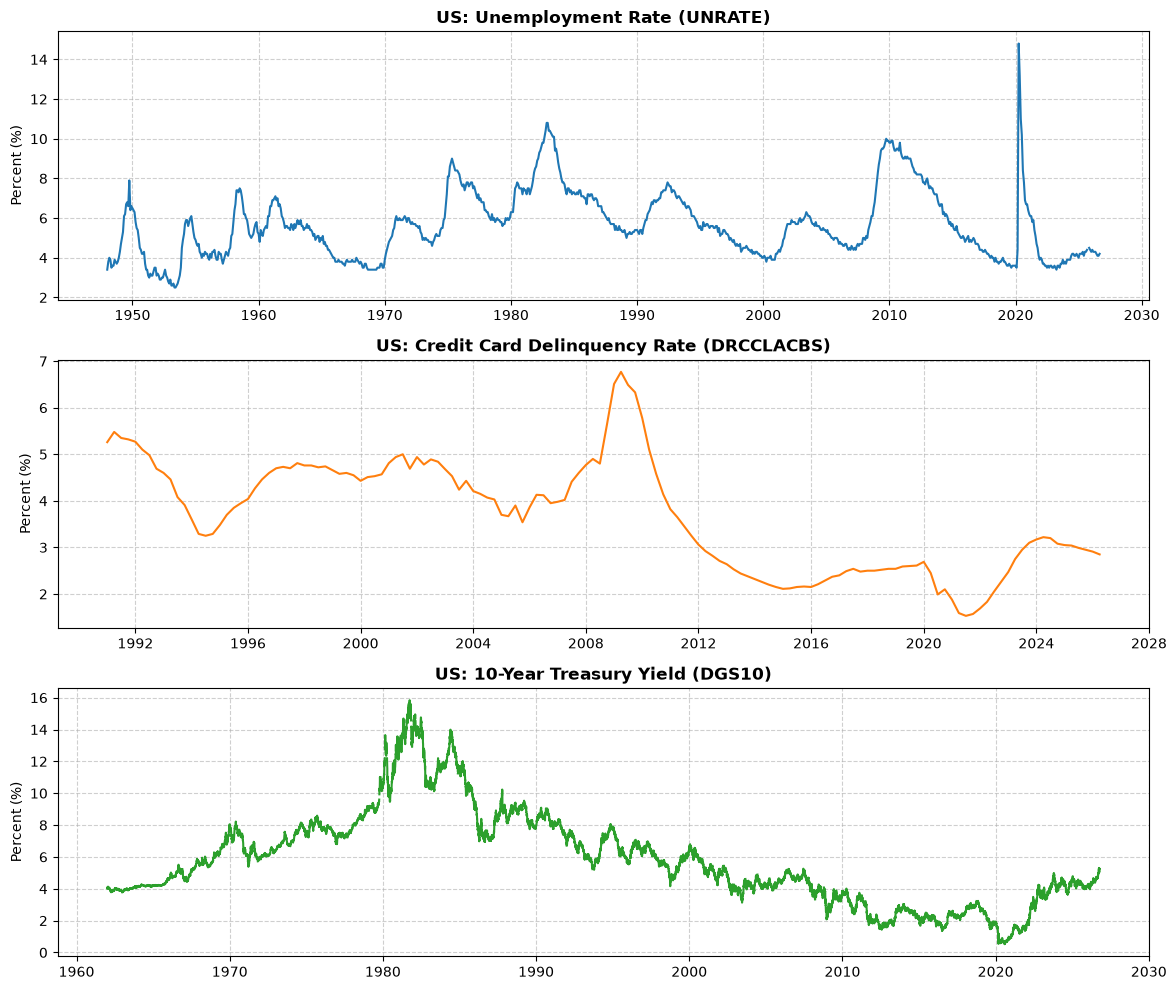

In [1]:
import os
from fredapi import Fred
import matplotlib.pyplot as plt

# .bashrc に定義された環境変数から API キーを取得
api_key = os.environ.get('FRED_API_KEY')

if not api_key:
    print("⚠️ エラー: 'FRED_API_KEY' が環境変数に見つかりません。")
    print("Jupyter Labを起動しているターミナルで `export FRED_API_KEY='あなたのキー'` を実行するか、カーネルを再起動してください。")
else:
    print("APIキーを読み込みました。データを取得中...")
    
    # FREDクライアントの初期化
    fred = Fred(api_key=api_key)

    # データの取得
    unrate = fred.get_series('UNRATE')
    delinquency = fred.get_series('DRCCLACBS')
    treasury = fred.get_series('DGS10')

    print("取得完了！グラフを描画します。")

    # グラフ描画（3段のサブプロット）
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

    axes[0].plot(unrate.index, unrate.values, color='#1f77b4', lw=1.5)
    axes[0].set_title('US: Unemployment Rate (UNRATE)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Percent (%)')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    axes[1].plot(delinquency.index, delinquency.values, color='#ff7f0e', lw=1.5)
    axes[1].set_title('US: Credit Card Delinquency Rate (DRCCLACBS)', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Percent (%)')
    axes[1].grid(True, linestyle='--', alpha=0.6)

    axes[2].plot(treasury.index, treasury.values, color='#2ca02c', lw=1.5)
    axes[2].set_title('US: 10-Year Treasury Yield (DGS10)', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Percent (%)')
    axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

APIキーを読み込みました。シンガポールのデータを取得中...
⚠️ ティッカー CCUSMA01SGM659N の取得に失敗しました: Bad Request.  The series does not exist.
取得完了！グラフを描画します。


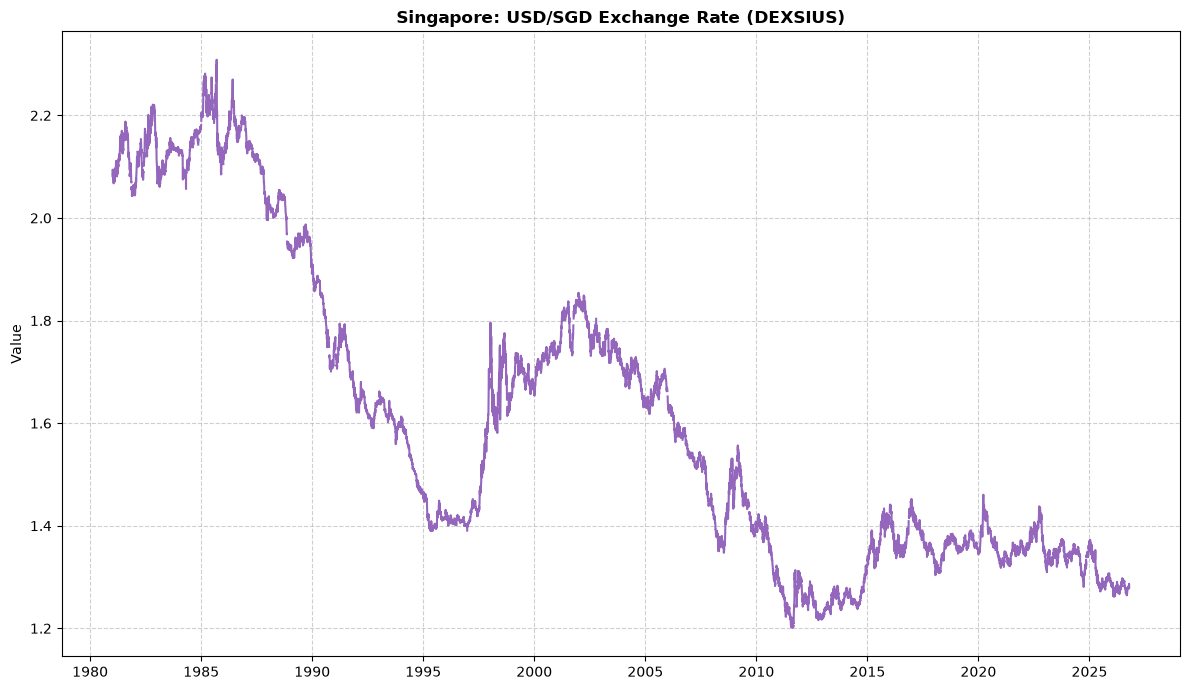

In [2]:
import os
from fredapi import Fred
import matplotlib.pyplot as plt

# 環境変数からAPIキーを取得
api_key = os.environ.get('FRED_API_KEY')

if not api_key:
    print("⚠️ エラー: 'FRED_API_KEY' が環境変数に見つかりません。")
else:
    print("APIキーを読み込みました。シンガポールのデータを取得中...")
    
    fred = Fred(api_key=api_key)

    # 現在もFREDで確実に対象が存在するシンガポールの主要ティッカー
    # - DEXSIUS: 米ドル/シンガポールドル（USD/SGD スポット為替レート）
    # - CCUSMA01SGM659N: シンガポールの消費者物価指数（CPI）
    sg_tickers = {
        'USD/SGD Exchange Rate (DEXSIUS)': 'DEXSIUS',
        'Consumer Price Index (CCUSMA01SGM659N)': 'CCUSMA01SGM659N'
    }

    sg_data = {}
    for name, ticker in sg_tickers.items():
        try:
            sg_data[name] = fred.get_series(ticker)
        except Exception as e:
            print(f"⚠️ ティッカー {ticker} の取得に失敗しました: {e}")

    if sg_data:
        print("取得完了！グラフを描画します。")

        # グラフ描画（2段のサブプロット）
        fig, axes = plt.subplots(len(sg_data), 1, figsize=(12, 7), sharex=False)
        if len(sg_data) == 1:
            axes = [axes]
            
        colors = ['#9467bd', '#8c564b']

        for i, (name, series) in enumerate(sg_data.items()):
            axes[i].plot(series.index, series.values, color=colors[i], lw=1.5)
            axes[i].set_title(f'Singapore: {name}', fontsize=12, fontweight='bold')
            axes[i].set_ylabel('Value')
            axes[i].grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()
    else:
        print("有効なデータが取得できませんでした。")